##**Deep Learning Project**
##**Customer Transactions**

**Hasan Raza Ali**  


##Building Classification Model Using Functional API

In [2]:
import sys
print(sys.executable)
print(sys.version)

c:\ProgramData\anaconda3\python.exe
3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [3]:
%pip install tensorflow pandas numpy matplotlib seaborn scikit-learn joblib

  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 1.3/384.1 MB 3.9 MB/s eta 0:01:39
   ---------------------------------------- 2.9/384.1 MB 5.8 MB/s eta 0:01:06
   -----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files

uploaded = files.upload()

# Save the uploaded file
for filename in uploaded.keys():
    print(f"Uploaded file: {filename}")


Saving Customer_Transactions.csv to Customer_Transactions.csv
Uploaded file: Customer_Transactions.csv


In [2]:
df = pd.read_csv('Customer_Transactions.csv')

df.head()

,customer_id,age,gender,country,annual_income,spending_score,num_purchases,avg_purchase_value,membership_years,website_visits_per_month,cart_abandon_rate,churned,feedback_text,last_purchase_date
0,1,37,Male,Germany,85886,14,18,41.20,6,20,0.95,0,Very satisfied with my purchase.,22/06/2025
1,2,40,Male,India,41041,4,10,31.73,4,29,0.21,0,Good quality and value for money.,17/10/2025
2,3,69,Female,Australia,143869,59,39,65.96,12,26,0.08,0,Excellent customer service.,01/07/2025
3,4,30,Male,UK,87261,45,34,51.87,12,7,0.61,0,Good quality and value for money.,17/08/2025
4,5,69,Female,UK,110678,40,38,59.64,13,16,0.49,0,Excellent customer service.,21/06/2025


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10000 non-null  int64  
 1   age                       10000 non-null  int64  
 2   gender                    10000 non-null  object 
 3   country                   10000 non-null  object 
 4   annual_income             10000 non-null  int64  
 5   spending_score            10000 non-null  int64  
 6   num_purchases             10000 non-null  int64  
 7   avg_purchase_value        10000 non-null  float64
 8   membership_years          10000 non-null  int64  
 9   website_visits_per_month  10000 non-null  int64  
 10  cart_abandon_rate         10000 non-null  float64
 11  churned                   10000 non-null  int64  
 12  feedback_text             10000 non-null  object 
 13  last_purchase_date        10000 non-null  object 
dtypes: floa

In [3]:
df.describe()

,customer_id,age,annual_income,spending_score,num_purchases,avg_purchase_value,membership_years,website_visits_per_month,cart_abandon_rate,churned
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,44.045800,86067.676100,50.924200,22.576000,47.447480,6.340500,15.578100,0.501216,0.109000
std,2886.89568,15.404669,38986.787991,28.753395,10.163639,11.205902,4.680657,8.655322,0.286836,0.311655
min,1.00000,18.000000,20028.000000,1.000000,1.000000,16.750000,0.000000,1.000000,0.000000,0.000000
25%,2500.75000,31.000000,55345.500000,26.000000,14.000000,39.500000,2.000000,8.000000,0.250000,0.000000
50%,5000.50000,44.000000,78339.500000,51.000000,22.000000,46.990000,6.000000,16.000000,0.510000,0.000000
75%,7500.25000,57.000000,115570.500000,75.000000,31.000000,55.080000,10.000000,23.000000,0.750000,0.000000
max,10000.00000,70.000000,179960.000000,100.000000,49.000000,83.270000,15.000000,30.000000,1.000000,1.000000


In [4]:
df.isnull().sum()

customer_id                 0
age                         0
gender                      0
country                     0
annual_income               0
spending_score              0
num_purchases               0
avg_purchase_value          0
membership_years            0
website_visits_per_month    0
cart_abandon_rate           0
churned                     0
feedback_text               0
last_purchase_date          0
dtype: int64

#Exploratory Data Analysis

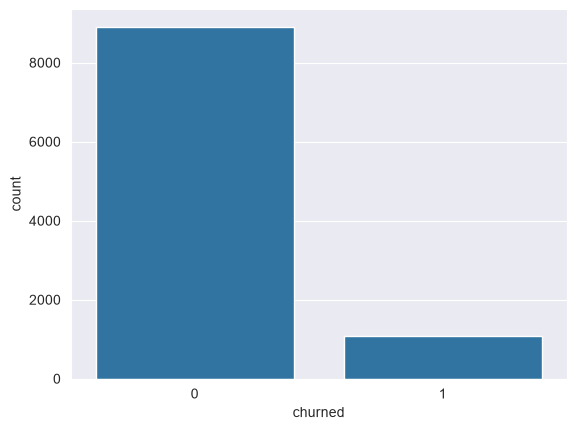

In [5]:
sns.countplot(x='churned', data=df)
plt.show()

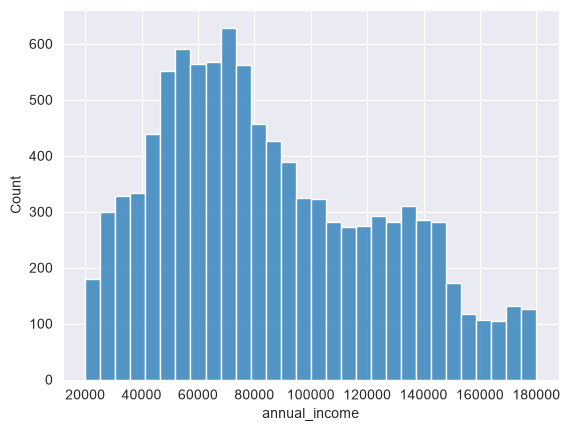

In [6]:
sns.histplot(df['annual_income'], bins=30)
plt.show()

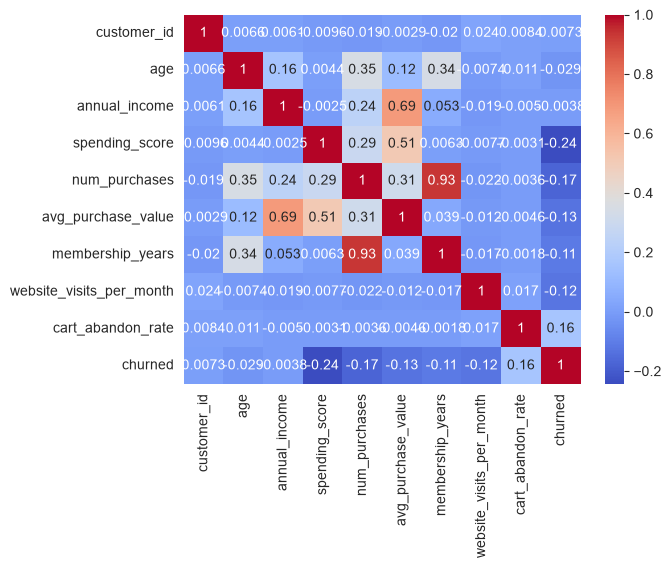

In [7]:
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm')
plt.show()

## Data Preprocessing

In [8]:
df['gender'] = df['gender'].map({'Female':0, 'Male':1})

In [9]:
df = pd.get_dummies(df, columns=['country'], drop_first=True, dtype=int)

In [10]:
df.head()

,customer_id,age,gender,annual_income,spending_score,num_purchases,avg_purchase_value,membership_years,website_visits_per_month,cart_abandon_rate,...,last_purchase_date,country_Brazil,country_Canada,country_France,country_Germany,country_India,country_Japan,country_South Africa,country_UK,country_USA
0,1,37,1,85886,14,18,41.20,6,20,0.95,...,22/06/2025,0,0,0,1,0,0,0,0,0
1,2,40,1,41041,4,10,31.73,4,29,0.21,...,17/10/2025,0,0,0,0,1,0,0,0,0
2,3,69,0,143869,59,39,65.96,12,26,0.08,...,01/07/2025,0,0,0,0,0,0,0,0,0
3,4,30,1,87261,45,34,51.87,12,7,0.61,...,17/08/2025,0,0,0,0,0,0,0,1,0
4,5,69,0,110678,40,38,59.64,13,16,0.49,...,21/06/2025,0,0,0,0,0,0,0,1,0


In [14]:
df['last_purchase_date'] = pd.to_datetime(df['last_purchase_date'], format='%d/%m/%Y')

In [17]:
if 'last_purchase_date' in df.columns:
    df['last_purchase_date'] = pd.to_datetime(df['last_purchase_date'], format='%d/%m/%Y')
    reference_date = df['last_purchase_date'].max()
    df['days_since_last_purchase'] = (reference_date - df['last_purchase_date']).dt.days
    df = df.drop('last_purchase_date', axis=1)
else:
    print("Yeh cell pehle chal chuka hai, dobara chalane ki zaroorat nahi.")

Yeh cell pehle chal chuka hai, dobara chalane ki zaroorat nahi.


In [18]:
df[['days_since_last_purchase']].head()

,days_since_last_purchase
0,127
1,10
2,118
3,71
4,128


In [19]:
X = df.drop(['churned', 'feedback_text'], axis=1)

# y = target
y = df['churned']

In [21]:
from sklearn.model_selection import train_test_split

In [22]:
X_train, X_Other, y_train, y_Other = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
# Split into validation and testing
X_val, X_test, y_val, y_test = train_test_split(X_Other, y_Other, test_size=0.5, random_state=42)

In [24]:
X_train.shape, X_val.shape, X_test.shape

((8000, 20), (1000, 20), (1000, 20))

In [25]:
y_train.shape, y_val.shape, y_test.shape

((8000,), (1000,), (1000,))

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [27]:
# List of numeric features
num_cols = ['age', 'annual_income', 'spending_score', 'num_purchases',
            'avg_purchase_value', 'membership_years', 'website_visits_per_month',
            'cart_abandon_rate', 'days_since_last_purchase']

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [28]:
from sklearn.utils import class_weight

cw = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {0: cw[0], 1: cw[1]}
print(class_weights)

{0: np.float64(0.5606166783461808), 1: np.float64(4.624277456647399)}


In [29]:
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [30]:
inputs = keras.layers.Input(shape=X_train.shape[1:], name="input_layer")
hidden1 = keras.layers.Dense(30, activation="relu", name="hidden_layer1")(inputs)
hidden2 = keras.layers.Dense(30, activation="relu", name="hidden_layer2")(hidden1)
concat = keras.layers.Concatenate()([inputs, hidden2])
output = keras.layers.Dense(1, activation="sigmoid", name="output_layer")(concat)
model = keras.Model(inputs=[inputs], outputs=[output])

In [31]:
from keras.optimizers import Adam

In [32]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [33]:
chk_pt=ModelCheckpoint("Customer_Transactions.keras",
              save_best_only=True,
              monitor="val_loss")

In [34]:
early_stop=EarlyStopping(monitor="val_loss",
                         patience=7,
                         restore_best_weights=True)

In [35]:
call_backs = [chk_pt, early_stop]

In [36]:
model.compile(loss="binary_crossentropy",
              optimizer=Adam(learning_rate=0.01),
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

In [37]:
history = model.fit(
    X_train, y_train,
    batch_size=32,
    epochs=100,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    callbacks=call_backs
)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5511 - auc: 0.5558 - loss: 21.1749 - val_accuracy: 0.1220 - val_auc: 0.5252 - val_loss: 66.3527
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6514 - auc: 0.7020 - loss: 5.4772 - val_accuracy: 0.8970 - val_auc: 0.7828 - val_loss: 0.6041
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6775 - auc: 0.7339 - loss: 6.0499 - val_accuracy: 0.1760 - val_auc: 0.5689 - val_loss: 25.2086
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7344 - auc: 0.8020 - loss: 4.0024 - val_accuracy: 0.9140 - val_auc: 0.7671 - val_loss: 0.7466
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7717 - auc: 0.8471 - loss: 1.7860 - val_accuracy: 0.9280 - val_auc: 0.8334 - val_loss: 0.5445
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7506 - auc: 0.8084 - loss: 3.9025 - val_accuracy: 0.9320 - val_auc: 0.9621 - val_loss: 0.2278
Epoch 7/100
250/250 ━━━━━━━━━━━

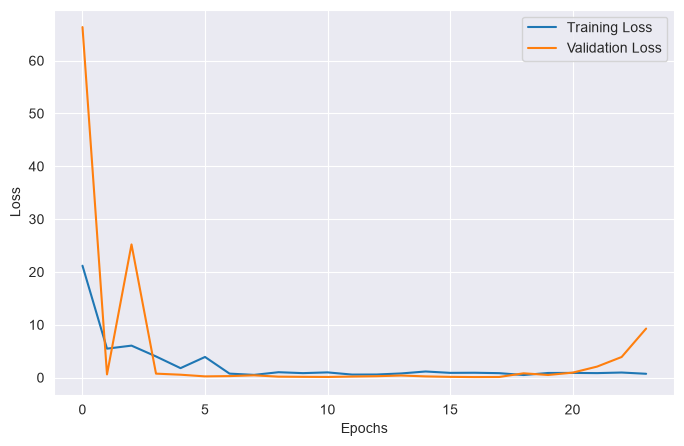

In [38]:
# Generate the loss vs val_loss
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

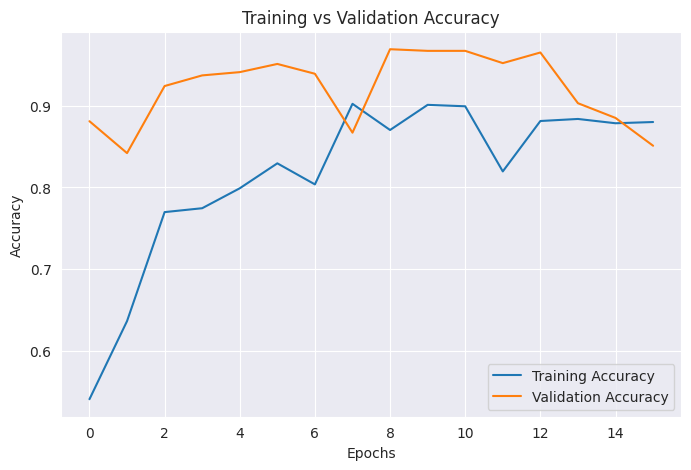

In [37]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

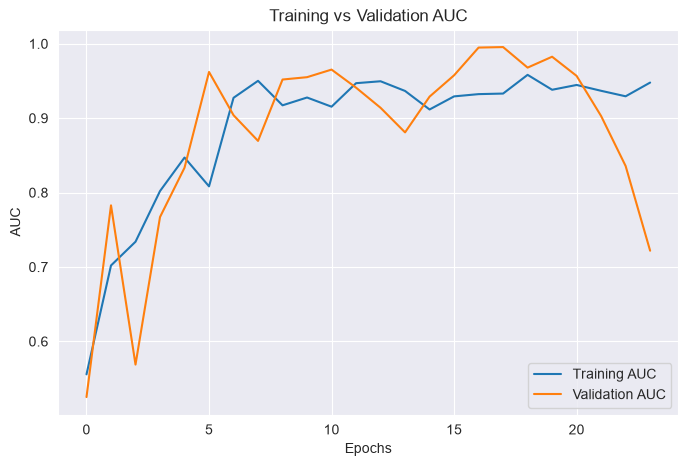

In [39]:
plt.figure(figsize=(8,5))
plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")
plt.xlabel("Epochs")
plt.ylabel("AUC")
plt.title("Training vs Validation AUC")
plt.legend()
plt.show()

In [40]:
from keras.models import load_model

In [41]:
from keras.models import load_model
model_load = load_model("Customer_Transactions.keras")

In [42]:
model_load.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_layer1       │ (None, 30)        │        630 │ input_layer[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_layer2       │ (None, 30)        │        930 │ hidden_layer1[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 50)        │          0 │ input_layer[0][0… │
│ (Concatenate)       │                   │            │ hidden_layer2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output_layer        │ (None, 1)         │         51 │ concatenate[0][0] │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,835 (18.89 KB)

 Trainable params: 1,611 (6.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,224 (12.60 KB)

In [43]:
test_loss, test_accuracy, test_auc = model_load.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}")
test_accuracy = test_accuracy * 100
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test AUC: {test_auc:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9690 - auc: 0.9969 - loss: 0.0896
Test Loss: 0.0896
Test Accuracy: 96.90%
Test AUC: 0.9969


In [44]:
# Probabilities
y_pred_prob = model_load.predict(X_test)

# Binary labels (threshold = 0.5)
y_pred = (y_pred_prob >= 0.5).astype(int)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [45]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[853  29]
 [  2 116]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       882
           1       0.80      0.98      0.88       118

    accuracy                           0.97      1000
   macro avg       0.90      0.98      0.93      1000
weighted avg       0.97      0.97      0.97      1000



In [46]:
val_loss, val_accuracy, val_auc = model_load.evaluate(X_val, y_val)
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy*100:.2f}%")
print(f"Validation AUC: {val_auc:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9640 - auc: 0.9948 - loss: 0.0961 
Validation Loss: 0.0961
Validation Accuracy: 96.40%
Validation AUC: 0.9948


In [47]:
test_loss, test_accuracy, test_auc = model_load.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy*100:.2f}%  |  Test AUC: {test_auc:.4f}")

y_pred_prob = model_load.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9690 - auc: 0.9969 - loss: 0.0896
Test Accuracy: 96.90%  |  Test AUC: 0.9969
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
[[853  29]
 [  2 116]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       882
           1       0.80      0.98      0.88       118

    accuracy                           0.97      1000
   macro avg       0.90      0.98      0.93      1000
weighted avg       0.97      0.97      0.97      1000



In [48]:
import joblib, json

joblib.dump(scaler, "churn_scaler.pkl")

meta = {
    "columns": list(X_train.columns),
    "num_cols": num_cols,
    "reference_date": str(reference_date.date())
}
with open("churn_meta.json", "w") as f:
    json.dump(meta, f)

print(meta["columns"])

['customer_id', 'age', 'gender', 'annual_income', 'spending_score', 'num_purchases', 'avg_purchase_value', 'membership_years', 'website_visits_per_month', 'cart_abandon_rate', 'country_Brazil', 'country_Canada', 'country_France', 'country_Germany', 'country_India', 'country_Japan', 'country_South Africa', 'country_UK', 'country_USA', 'days_since_last_purchase']
